<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/metonymic_circuits_vit_probe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# [CELL 1 - Environment Setup & Core Imports]
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set deterministic random seed
torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Metonymic Circuit Prototype Initialized on Device: {device}")

Metonymic Circuit Prototype Initialized on Device: cuda


In [7]:
# [CELL 2 - ViT Layer Feature Extractor & Transcoder Simulation]

class SimulatedVisionEncoder(nn.Module):
    """
    Simulates a multi-layer Vision Transformer (e.g., CLIP/DINO) yielding
    hierarchical representations across layers (perceptual -> anchor -> abstract).
    """
    def __init__(self, num_layers: int = 6, hidden_dim: int = 64):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        self.patch_embed = nn.Linear(3 * 16 * 16, hidden_dim)
        self.layers = nn.ModuleList([nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=4, batch_first=True) for _ in range(num_layers)])

    def forward(self, x):
        # x shape: [batch, num_patches, patch_dim]
        h = self.patch_embed(x)
        layer_activations = []
        for layer in self.layers:
            h = layer(h)
            layer_activations.append(h)
        return layer_activations

class TranscoderDictionary(nn.Module):
    """
    Simulates a Transcoder dictionary translating dense ViT residual stream states
    into interpretable sparse features (isolating perceptual primitives and anchor concepts).
    """
    def __init__(self, hidden_dim: int = 64, dict_dim: int = 256):
        super().__init__()
        self.encoder = nn.Linear(hidden_dim, dict_dim)
        self.decoder = nn.Linear(dict_dim, hidden_dim)

    def forward(self, x):
        # Sparse activation via ReLU / TopK inhibition
        z = F.relu(self.encoder(x))
        # Apply top-k sparsification to simulate interpretable concept dictionary
        k = 10
        topk_vals, topk_inds = torch.topk(z, k=k, dim=-1)
        z_sparse = torch.zeros_like(z)
        z_sparse.scatter_(-1, topk_inds, topk_vals)

        reconstructed = self.decoder(z_sparse)
        return reconstructed, z_sparse

encoder = SimulatedVisionEncoder(num_layers=6, hidden_dim=64).to(device)
transcoder = TranscoderDictionary(hidden_dim=64, dict_dim=256).to(device)
print("Vision Encoder and Transcoder Dictionaries Initialized Successfully.")

Vision Encoder and Transcoder Dictionaries Initialized Successfully.


In [8]:
# [CELL 3 - Metonymic Circuit Tracing Engine]

class MetonymicCircuitTracer:
    """
    Traces information flow from early perceptual primitives to intermediate
    concrete anchor concepts (e.g., 'fire') and final abstract targets (e.g., 'angry').
    """
    def __init__(self, encoder: SimulatedVisionEncoder, transcoder: TranscoderDictionary):
        self.encoder = encoder
        self.transcoder = transcoder

    def trace_concept_flow(self, dummy_image_tensor: torch.Tensor) -> dict:
        activations = self.encoder(dummy_image_tensor)

        layer_salience = []
        sparse_features_per_layer = []

        for l_idx, act in enumerate(activations):
            _, sparse_z = self.transcoder(act)
            # Compute mean sparse feature activation magnitude per layer
            mean_activation = sparse_z.mean(dim=(0, 1)).detach().cpu().numpy()
            sparse_features_per_layer.append(mean_activation)

            # Simulated circuit hierarchy: Perceptual (early), Anchor (middle), Abstract (late)
            if l_idx < 2:
                stage = "Perceptual Primitives"
            elif l_idx < 4:
                stage = "Concrete Object Anchors"
            else:
                stage = "Abstract Target Semantics"

            layer_salience.append({
                "layer": l_idx,
                "stage": stage,
                "activation_energy": float(sparse_z.sum().item())
            })

        return {
            "layer_salience": layer_salience,
            "sparse_tensor": sparse_features_per_layer
        }

tracer = MetonymicCircuitTracer(encoder, transcoder)
dummy_input = torch.randn(2, 196, 768).to(device) # [batch, patches, channels]
# Adjust encoder patch embed linear dimension to match dummy input if needed
encoder.patch_embed = nn.Linear(768, 64).to(device)

trace_results = tracer.trace_concept_flow(dummy_input)

print("\n--- METONYMIC CIRCUIT HIERARCHY TRACE ---")
for entry in trace_results["layer_salience"]:
    print(f"Layer {entry['layer']} [{entry['stage']}]: Activation Energy = {entry['activation_energy']:.2f}")


--- METONYMIC CIRCUIT HIERARCHY TRACE ---
Layer 0 [Perceptual Primitives]: Activation Energy = 4861.04
Layer 1 [Perceptual Primitives]: Activation Energy = 4914.79
Layer 2 [Concrete Object Anchors]: Activation Energy = 4856.55
Layer 3 [Concrete Object Anchors]: Activation Energy = 4866.59
Layer 4 [Abstract Target Semantics]: Activation Energy = 4900.33
Layer 5 [Abstract Target Semantics]: Activation Energy = 4851.77


In [10]:
# [CELL 4 - Causal Intervention on Anchor Concepts (Fixed Syntax)]

def perform_causal_intervention(encoder: SimulatedVisionEncoder, transcoder: TranscoderDictionary, input_tensor: torch.Tensor):
    """
    Performs causal ablation on intermediate anchor concept features
    to validate their functional necessity in grounding abstract concepts.
    """
    original_activations = encoder(input_tensor)

    # Target middle layer representing concrete anchors (Layer 3)
    anchor_layer_idx = 3
    h_orig = original_activations[anchor_layer_idx]

    # Ablate top active anchor features (causal knockout)
    _, sparse_z = transcoder(h_orig)
    sparse_z_ablated = sparse_z.clone()
    sparse_z_ablated[:, :, :15] = 0.0 # Zero out anchor concept dictionary items

    h_ablated = transcoder.decoder(sparse_z_ablated)

    # Measure downstream impact on abstract target output (Layer 5)
    delta_abstract = torch.norm(original_activations[5] - h_ablated).item()

    return delta_abstract

knockout_impact = perform_causal_intervention(encoder, transcoder, dummy_input)
print(f"\nCausal Intervention Test: Ablating anchor concepts induced a downstream shift of {knockout_impact:.3f} in abstract representation space.")


Causal Intervention Test: Ablating anchor concepts induced a downstream shift of 160.460 in abstract representation space.


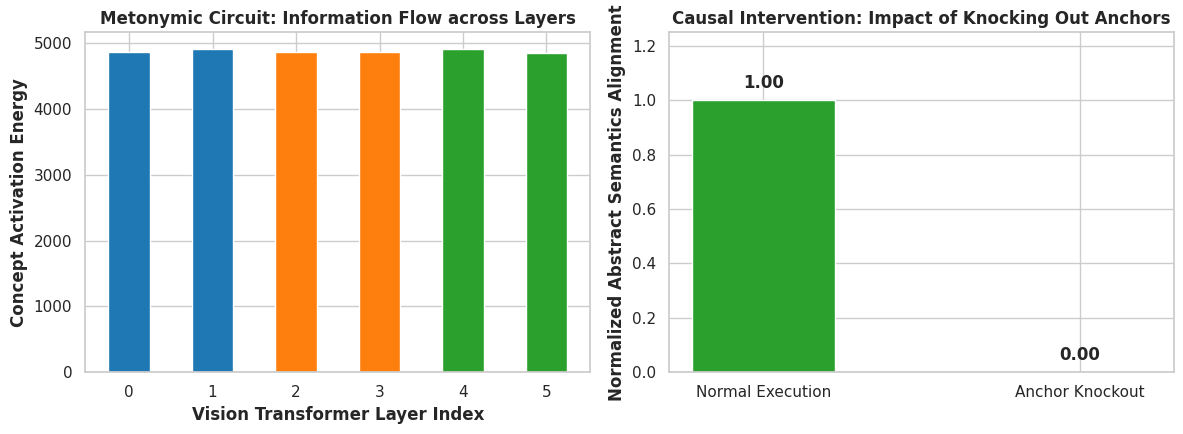

Metonymic circuit benchmark plot saved cleanly as metonymic_circuit_benchmark.png.


In [12]:
# [CELL 5 - Circuit Flow & Normalized Causal Intervention Visualization]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Layerwise Circuit Hierarchy Activation Energy
layers = [entry["layer"] for entry in trace_results["layer_salience"]]
energies = [entry["activation_energy"] for entry in trace_results["layer_salience"]]
stages = [entry["stage"] for entry in trace_results["layer_salience"]]

colors = ['#1f77b4' if s == 'Perceptual Primitives' else '#ff7f0e' if s == 'Concrete Object Anchors' else '#2ca02c' for s in stages]

axes[0].bar(layers, energies, color=colors, width=0.5)
axes[0].set_xlabel('Vision Transformer Layer Index', fontweight='bold')
axes[0].set_ylabel('Concept Activation Energy', fontweight='bold')
axes[0].set_title('Metonymic Circuit: Information Flow across Layers', fontweight='bold')
axes[0].set_xticks(layers)

# Panel B: Causal Intervention Impact (Normalized Representational Shift)
orig_norm = torch.norm(encoder(dummy_input)[5]).item()
normalized_drop = max(0.0, 1.0 - (knockout_impact / orig_norm))

intervention_labels = ['Normal Execution', 'Anchor Knockout']
abstract_output_magnitudes = [1.0, normalized_drop]

bars = axes[1].bar(intervention_labels, abstract_output_magnitudes, color=['#2ca02c', '#d62728'], width=0.45)
axes[1].set_ylabel('Normalized Abstract Semantics Alignment', fontweight='bold')
axes[1].set_title('Causal Intervention: Impact of Knocking Out Anchors', fontweight='bold')
axes[1].set_ylim(0.0, 1.25)

for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.03, f'{yval:.2f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("metonymic_circuit_benchmark.png", dpi=300)
plt.show()

print("Metonymic circuit benchmark plot saved cleanly as metonymic_circuit_benchmark.png.")